# Notebook 04 — SuperSimpleNet

## Research questions and execution status
Can learned discrimination of spatially masked feature perturbations improve real defect detection, calibration and inference cost? Does the feature adapter help? Can a smaller extractor preserve useful discrimination?

This chronological architecture and pilot record precedes development selection and official test access. Cells explicitly labeled **artifact replay** load genuine earlier measurements; subsequent diagnostic cells execute live. The complete benchmark is **not complete** at this point. Earlier models, records and partitions are preserved.

## Original architecture and sources
Read the [ICPR paper, arXiv v2](https://arxiv.org/html/2408.03143v2) alongside the [official source pinned at 98ab4d5fbdcdef528fafbc42e4b5ee15f08f5a7d](https://github.com/blaz-r/SuperSimpleNet/tree/98ab4d5fbdcdef528fafbc42e4b5ee15f08f5a7d). The source's later JIMS default uses unadapted classifier features; here the original ICPR adapted-classifier path is explicit. MIT attribution is retained under `docs/third_party/`.

Basic CNN learned normal/synthetic RGB discrimination. The autoencoder minimized reconstruction error. PatchCore stored normal local features and searched nearest neighbors. SuperSimpleNet instead learns dense and image-level discrimination after frozen pretrained feature extraction, with synthetic perturbations inserted into adapted features rather than RGB images. Inference needs no memory-bank search and no synthetic generator.

## Mathematical flow
Let $F_2,F_3$ be frozen ImageNet features. First align both to $64\times64$, concatenate, and apply average pooling: $z=P_3[U_2F_2(x);U_4F_3(x)]$. A learned pointwise affine adapter gives $a=W_a*z+b_a$.

Training duplicates $a$ and independently perturbs **both** copies: $\tilde a=a+M\odot\epsilon$, $\epsilon\sim\mathcal N(0,0.015^2 I)$. $M=1[p>0.2]$ for Perlin gradient noise $p$, with approximately half of masks forced empty. Dense target is $M$ and image target is $y=1[\max M>0]$. Clean and altered features share the same normal source distribution. No real defects enter training.

The segmentation branch is $s=W_2*\operatorname{LeakyReLU}(\operatorname{BN}(W_1*\tilde a))$. The detector computes $d=\operatorname{ReLU}(\operatorname{BN}(W_5*[\tilde a;\operatorname{stopgrad}(s)]))$ and a linear scalar from max/mean pooling of both $d$ and $s$. Detaching every segmentation route prevents classifier gradients from corrupting localization, while classification still updates the adapter through its feature input.

With focal $\ell_f(p,t)=-(1-p_t)^4\log p_t$, optimize $L=L_{\rm margin}+L_f(s,M)+L_f(c,y)$. The margin averages normal and anomaly pixels **separately**, using $\max(0,s+0.5)$ and $\max(0,0.5-s)$. Empty-class means contribute zero. AdamW uses adapter LR $10^{-4}$, head LR $2\cdot10^{-4}$, group-specific decay, and fixed scheduler fractions .8/.9. Final pixel map is bilinear-upsampled raw segmentation logits followed by Gaussian smoothing $\sigma=4$. The detector produces a separate raw image logit; max/top1% map rules are development candidates, not interchangeable probabilities.

Complexity is fixed per image: frozen CNN plus pointwise adapter/segmentation and a 5x5 classifier convolution. Unlike PatchCore, inference does not scale with normal memory size. Dense 64-grid heads and feature-cache IO can still be expensive.

## Fidelity and intentional differences
Reference widths are 1536/1024/128 with WideResNet50-2 **ImageNet V1**. Lite uses ResNet18 V1 and 384/256/32. We preserve established whole-image 256 geometry and normal-only partitions, use reduced epoch/batch/seed budgets, and add gradient clipping at10. Our independently seeded Perlin implementation is not RNG-identical to the official one. Raw logits avoid official test-derived min/max normalization. These reduced-budget models are not claimed to reproduce paper results. See the complete preregistered [protocol](../reports/supersimplenet/protocol.md).


In [1]:
from pathlib import Path
import sys,json,time,inspect
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
import numpy as np,pandas as pd,matplotlib.pyplot as plt,torch,psutil
from anomaly_detection.supersimplenet import *
from anomaly_detection.ssn_research import experiment,feature_cache,model_for,predict
from anomaly_detection.cnn_research import read_partition,require_fitting,load_resized
from anomaly_detection.data import CATEGORIES,sha256
torch.set_num_threads(4)
assert torch.cuda.is_available()
torch.backends.cuda.matmul.allow_tf32=False
print(torch.__version__,torch.cuda.get_device_name(0))
print('VRAM GiB:',torch.cuda.get_device_properties(0).total_memory/2**30)
print('RAM GiB:',psutil.virtual_memory().total/2**30)


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


2.11.0+cu128 NVIDIA GeForce RTX 4060 Laptop GPU
VRAM GiB: 7.99560546875
RAM GiB: 31.70067596435547


## Architecture illustration
Only the training path injects noise. Calibration and inference follow the clean adapted-feature path. All masks below are synthetic feature-space targets.

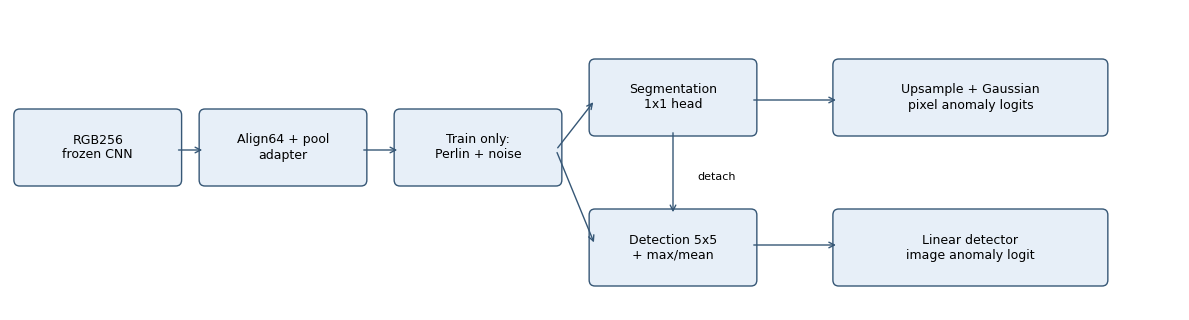

In [2]:
from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(12,3.3));ax.set(xlim=(0,12),ylim=(0,3));ax.axis('off')
boxes=[(.1,1.3,1.6,'RGB256\nfrozen CNN'),(2,1.3,1.6,'Align64 + pool\nadapter'),(4,1.3,1.6,'Train only:\nPerlin + noise'),(6,1.8,1.6,'Segmentation\n1x1 head'),(6,.3,1.6,'Detection 5x5\n+ max/mean'),(8.5,1.8,2.7,'Upsample + Gaussian\npixel anomaly logits'),(8.5,.3,2.7,'Linear detector\nimage anomaly logit')]
for x,y,w,t in boxes:
    ax.add_patch(FancyBboxPatch((x,y),w,.65,boxstyle='round,pad=.06',fc='#e7eff8',ec='#365776'));ax.text(x+w/2,y+.325,t,ha='center',va='center',fontsize=9)
for a,b in [((1.7,1.6),(2,1.6)),((3.6,1.6),(4,1.6)),((5.6,1.6),(6,2.1)),((5.6,1.6),(6,.65)),((7.6,2.1),(8.5,2.1)),((7.6,.65),(8.5,.65)),((6.8,1.8),(6.8,.95))]:
    ax.annotate('',xy=b,xytext=a,arrowprops=dict(arrowstyle='->',color='#365776'))
ax.text(7.05,1.3,'detach',fontsize=8);fig.tight_layout()
fig.savefig(ROOT/'reports/supersimplenet/architecture.svg');plt.show()


## Dataset isolation and preprocessing
The shared loader verifies seed-2026 manifests. Fitting and development contain normals only. Pilot fitting/probe sources are disjoint; development normals are never perturbed in their clean diagnostic distribution. Reserved calibration and official test data are not opened in this notebook stage. PIL whole-image RGB bilinear resizing to256 is followed by the correct ImageNet V1 normalization.


In [3]:
fit=read_partition('fit','bottle');dev=read_partition('development','bottle')
require_fitting(fit)
assert not set(fit.path)&set(dev.path)
print('Categories:',CATEGORIES)
print('Bottle fitting/development:',len(fit),len(dev))
print('Pilot fitting/probe/development counts:',32,8,16)


Categories: ('bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper')
Bottle fitting/development: 147 31
Pilot fitting/probe/development counts: 32 8 16


## Implementation: frozen feature extraction and alignment
The actual reusable implementation is exposed below. Upsampling occurs before pooling; existing PatchCore caches have incompatible geometry and are not reused. Deterministic per-image caches are reused across trials/seeds.

In [4]:
print(inspect.getsource(SSNExtractor))
print(inspect.getsource(aggregate_features))


class SSNExtractor(nn.Module):
    """Frozen ImageNet V1 layers 2/3, upscale FIRST to 64, then pool 3x3.

    PatchCore's pooled 32-grid cache is NOT compatible with this computation.
    Uses official V1 normalization with whole-image 256 geometry (paper setting).
    """
    def __init__(self,backbone='resnet18',pretrained=True):
        super().__init__()
        if backbone not in ['resnet18','wide_resnet50_2']:raise ValueError('Unsupported backbone')
        self.backbone=backbone
        weights=ResNet18_Weights.IMAGENET1K_V1 if backbone=='resnet18' else Wide_ResNet50_2_Weights.IMAGENET1K_V1
        self.weight_url=weights.url
        self.channels=384 if backbone=='resnet18' else 1536
        network=(resnet18 if backbone=='resnet18' else wide_resnet50_2)(weights=None)
        if pretrained:
            name=Path(weights.url).name
            local=Path(__file__).resolve().parents[2]/'checkpoints/pretrained'/name
            path=local if local.exists() else Path(torch.hub.get_d

## Feature anomaly implementation and exact targets
Perlin noise uses smooth gradient-lattice interpolation. A binary spatial mask gates independently sampled channel noise; its actual nonempty support determines the image label. The clean cached feature tensor is not modified.

In [5]:
print(inspect.getsource(perlin_noise))
print(inspect.getsource(feature_anomalies))


def perlin_noise(height,width,res_y,res_x,generator):
    """Quintic-interpolated random gradient lattice, not resized white noise."""
    y=torch.arange(height,dtype=torch.float32)*res_y/height
    x=torch.arange(width,dtype=torch.float32)*res_x/width
    yy,xx=torch.meshgrid(y,x,indexing='ij')
    iy=yy.long();ix=xx.long();dy=yy-iy;dx=xx-ix
    angles=2*math.pi*torch.rand(res_y+1,res_x+1,generator=generator)
    gy,gx=angles.sin(),angles.cos()
    def dot(oy,ox):return gy[iy+oy,ix+ox]*(dy-oy)+gx[iy+oy,ix+ox]*(dx-ox)
    fade=lambda t:6*t**5-15*t**4+10*t**3
    upper=torch.lerp(dot(0,0),dot(0,1),fade(dx))
    lower=torch.lerp(dot(1,0),dot(1,1),fade(dx))
    return math.sqrt(2)*torch.lerp(upper,lower,fade(dy))

def feature_anomalies(adapted,mask_generator,noise_generator,noise_std=.015,threshold=.2,normal_probability=.5):
    """Duplicate features; independent Perlin/no-anomaly decisions for BOTH copies.

    All source features are fitting normals, so real-anomaly masks are empty.
   

## Adapter, segmentation and detection heads; losses and training step
The source shows exactly where classification gradients stop. Synthetic generation is explicit and cannot occur in ordinary forward/inference. Margin and focal losses are implemented directly.

In [6]:
print(inspect.getsource(SuperSimpleHeads))
print(inspect.getsource(focal_loss));print(inspect.getsource(training_loss))
print(inspect.getsource(optimizer_for));print(inspect.getsource(anomaly_maps))
from anomaly_detection.ssn_research import train_epoch
print(inspect.getsource(train_epoch))


class SuperSimpleHeads(nn.Module):
    """Reference: C=1536, seg=1024, detection=128; Lite: C=384,256,32.

    The original ICPR formulation uses adapted features for BOTH heads. Every
    classification route through the segmentation map is detached by default;
    classification can still update the adapter through its feature input.
    """
    def __init__(self,channels=384,seg_width=256,det_width=32,adapter_trainable=True,stop_grad=True):
        super().__init__()
        self.adapter=nn.Conv2d(channels,channels,1)
        self.seg=nn.Sequential(nn.Conv2d(channels,seg_width,1),nn.BatchNorm2d(seg_width),
            nn.LeakyReLU(.2),nn.Conv2d(seg_width,1,1,bias=False))
        self.det=nn.Sequential(nn.Conv2d(channels+1,det_width,5,padding=2),nn.BatchNorm2d(det_width),nn.ReLU())
        self.fc=nn.Linear(2*det_width+2,1)
        self.stop_grad=stop_grad
        for module in self.modules():
            if isinstance(module,(nn.Conv2d,nn.Linear)):nn.init.xavier_normal_(module.weigh

## Initial verification and chronological pilot: artifact replay
Five CPU tests passed for feature shapes/freezing, exact perturbation support, losses/gradients, detached classifier routing, checkpoint replay, score orientation and aggregation. The following results were measured by `scripts/pilot_supersimplenet.py`; this cell replays those artifacts and does not claim to retrain them live.

**Hypothesis R:** the reference-width architecture fits safely and is affordable for45 fits. **Hypothesis L:** 20 Lite epochs can learn the reference perturbation on32 fitting normals. Neither hypothesis uses official defect data.

{'layer_shapes': [[4, 512, 32, 32], [4, 1024, 16, 16]], 'aggregated_shape': [4, 1536, 64, 64], 'segmentation_shape': [8, 1, 64, 64], 'detection_shape': [8], 'head_parameters': 8856835, 'mean_step_seconds': 0.15902596000014455, 'projected_40_epoch_45_fit_training_seconds': 12270.443073611154, 'training_resources': {'seconds': 2.579084100005275, 'cpu_initial_rss_bytes': 1615908864, 'cpu_peak_rss_bytes': 2188419072, 'cpu_peak_increment_bytes': 572510208, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 1674352640, 'peak_gpu_reserved_bytes': 2629828608}}
Lite parameters: 555331 resources: {'seconds': 16.389204599996447, 'cpu_initial_rss_bytes': 2256863232, 'cpu_peak_rss_bytes': 2349768704, 'cpu_peak_increment_bytes': 92905472, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 1281359872}
Checkpoint replay exact: True


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.390625,0.448657,0.0,0.0,0.0,0.0,"[[8, 0], [8, 0]]",0.17782,0.05638,0.284223
max,0.59375,0.660218,0.125,0.125,0.5,0.2,"[[7, 1], [7, 1]]",0.17782,0.613795,0.367035
top1pct,0.59375,0.643029,0.0,0.0,0.0,0.0,"[[8, 0], [8, 0]]",0.17782,0.540258,0.385785


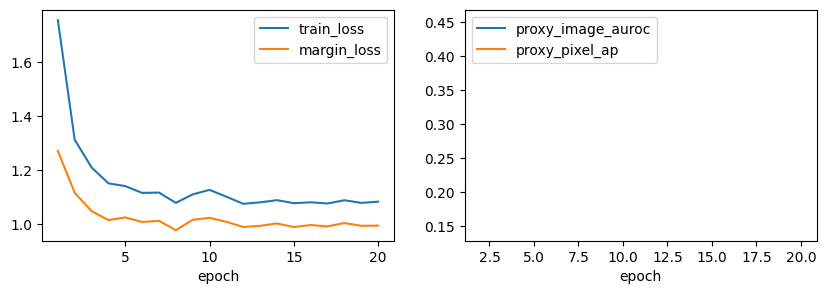

In [7]:
reference=json.loads((ROOT/'reports/supersimplenet/reference_feasibility.json').read_text())
pilot=json.loads((ROOT/'reports/supersimplenet/runs/04-pilot-lite-bottle-s2026-v1-result.json').read_text())
print({k:reference[k] for k in ['layer_shapes','aggregated_shape','segmentation_shape','detection_shape','head_parameters','mean_step_seconds','projected_40_epoch_45_fit_training_seconds','training_resources']})
print('Lite parameters:',pilot['parameters'],'resources:',pilot['resources'])
print('Checkpoint replay exact:',pilot['checkpoint_replay_exact'])
display(pd.DataFrame(pilot['development']['candidates']).T)
h=pd.DataFrame(pilot['history']);fig,axes=plt.subplots(1,2,figsize=(10,3))
h.plot(x='epoch',y=['train_loss','margin_loss'],ax=axes[0]);h.plot(x='epoch',y=['proxy_image_auroc','proxy_pixel_ap'],ax=axes[1]);plt.show()


**Measured interpretation and decision:** the reference path fits memory but projects beyond the prespecified 90-minute training budget, so it is rejected for broad study. Lite losses decrease but the margin stays near1, image discrimination is below chance and localization AP remains weak on this tiny proxy. This does not establish useful learning. Do not launch the all-category benchmark.

## Bounded diagnosis: stronger planned perturbation — live training
**Hypothesis N:** the planned .05 standard deviation provides a more learnable signal than .015 in the reduced-width, short-budget pilot. All other settings, seed, 32 normal fitting sources, eight disjoint probe sources and 16 clean development normals are unchanged. This is one predeclared magnitude candidate, not a search over real defects. The following code performs training live and preserves every epoch and checkpoint.

In [8]:
config=dict(backbone='resnet18',channels=384,seg_width=256,det_width=32,adapter_trainable=True,
    noise_std=.05,loss='margin_focal',seed=2026,batch_size=8,extraction_batch=8,epochs=20,
    validation_every=2,hypothesis='Larger planned feature perturbations improve learnability under the same bounded Lite pilot')
extractor=SSNExtractor('resnet18').cuda()
diagnostic=experiment('04-pilot-lite-noise05-bottle-s2026-v1','bottle',config,extractor,phase='pilot',pilot=True)
display(pd.DataFrame(diagnostic['development']['candidates']).T)
print('Checkpoint exact:',diagnostic['checkpoint_replay_exact'],'resources:',diagnostic['resources'])


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.7844929099082947, "gradient_norm": 17.29622519016266, "synthetic_fraction": 0.5, "target_pixel_fraction": 0.12175369262695312, "segmentation_focal": 0.19640105217695236, "margin_loss": 1.2721602320671082, "detection_focal": 0.3159316536039114, "train_epoch_seconds": 1.4159711000029347, "epoch": 1, "elapsed_seconds": 3.2109314000044833}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.3358725607395172, "gradient_norm": 7.202768921852112, "synthetic_fraction": 0.484375, "target_pixel_fraction": 0.12669754028320312, "segmentation_focal": 0.128070667386055, "margin_loss": 1.1239597499370575, "detection_focal": 0.08384212758392096, "train_epoch_seconds": 0.6243567000055918, "proxy_objective": 0.13315649316656092, "proxy_image_auroc": 0.21875, "proxy_pixel_ap": 0.1475629863331218, "proxy_loss": 1.1921768188476562, "normal_map_focal": 0.045053429901599884, "normal_head_focal": 0.003603713121265173, "epoch": 2, "elapsed_seconds": 4.507210300005681}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.217642217874527, "gradient_norm": 6.130073189735413, "synthetic_fraction": 0.578125, "target_pixel_fraction": 0.14192581176757812, "segmentation_focal": 0.09209035336971283, "margin_loss": 1.0510376989841461, "detection_focal": 0.07451416738331318, "train_epoch_seconds": 0.5579832999937935, "epoch": 3, "elapsed_seconds": 5.0698300000003655}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.1314653754234314, "gradient_norm": 3.6242160201072693, "synthetic_fraction": 0.53125, "target_pixel_fraction": 0.13655471801757812, "segmentation_focal": 0.07207253202795982, "margin_loss": 1.0037522912025452, "detection_focal": 0.055640559643507004, "train_epoch_seconds": 0.5726058000000194, "proxy_objective": 0.1976935802768054, "proxy_image_auroc": 0.328125, "proxy_pixel_ap": 0.16726216055361073, "proxy_loss": 1.32879638671875, "normal_map_focal": 0.03737542778253555, "normal_head_focal": 0.0005760792410001159, "epoch": 4, "elapsed_seconds": 6.219728700001724}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.1084512770175934, "gradient_norm": 3.3367320895195007, "synthetic_fraction": 0.390625, "target_pixel_fraction": 0.0971221923828125, "segmentation_focal": 0.0603802427649498, "margin_loss": 0.999319538474083, "detection_focal": 0.04875150602310896, "train_epoch_seconds": 0.5903220000036526, "epoch": 5, "elapsed_seconds": 6.816985900004511}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 1.0667344331741333, "gradient_norm": 2.3679280877113342, "synthetic_fraction": 0.4375, "target_pixel_fraction": 0.1143798828125, "segmentation_focal": 0.04932264145463705, "margin_loss": 0.9720984846353531, "detection_focal": 0.045313342474401, "train_epoch_seconds": 0.6172732999984873, "proxy_objective": 0.26571757169203947, "proxy_image_auroc": 0.359375, "proxy_pixel_ap": 0.172060143384079, "proxy_loss": 1.2699373960494995, "normal_map_focal": 0.0219881534576416, "normal_head_focal": 0.0007623948622494936, "epoch": 6, "elapsed_seconds": 8.001712400000542}


... (12 outputs left out)

{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 0.9350047260522842, "gradient_norm": 2.111547291278839, "synthetic_fraction": 0.375, "target_pixel_fraction": 0.09683990478515625, "segmentation_focal": 0.03462004102766514, "margin_loss": 0.8685614466667175, "detection_focal": 0.031823225785046816, "train_epoch_seconds": 0.5013478000037139, "epoch": 19, "elapsed_seconds": 18.7183623000019}


{"experiment": "04-pilot-lite-noise05-bottle-s2026-v1", "train_loss": 0.93631611764431, "gradient_norm": 2.7716596126556396, "synthetic_fraction": 0.484375, "target_pixel_fraction": 0.13257598876953125, "segmentation_focal": 0.035075065679848194, "margin_loss": 0.8647525161504745, "detection_focal": 0.03648852836340666, "train_epoch_seconds": 0.5458471999954781, "proxy_objective": 0.5382721065546681, "proxy_image_auroc": 0.8125, "proxy_pixel_ap": 0.264044213109336, "proxy_loss": 0.9493485689163208, "normal_map_focal": 0.02759729139506817, "normal_head_focal": 0.009813559241592884, "epoch": 20, "elapsed_seconds": 19.7359401000067}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,normal_development_q95,objective
head,0.8125,0.821925,0.125,0.0,1.0,0.222222,"[[8, 0], [7, 1]]",0.264044,-0.204896,0.538272
max,0.734375,0.758631,0.5,0.25,0.666667,0.571429,"[[6, 2], [4, 4]]",0.264044,0.565563,0.44921
top1pct,0.78125,0.768651,0.25,0.125,0.666667,0.363636,"[[7, 1], [6, 2]]",0.264044,0.463735,0.503897


Checkpoint exact: True resources: {'seconds': 17.955437799995707, 'cpu_initial_rss_bytes': 949690368, 'cpu_peak_rss_bytes': 2014621696, 'cpu_peak_increment_bytes': 1064931328, 'cpu_sampling_seconds': 0.05, 'peak_gpu_allocated_bytes': 761477632, 'peak_gpu_reserved_bytes': 970981376}


## Synthetic feature diagnostics — live inference
Plot a clean feature channel, planted mask, perturbation magnitude and predicted dense map. These are feature-space diagnostics, not real industrial anomaly evidence. The fixed seeded generator supplies exactly the same proxy support as development scoring.

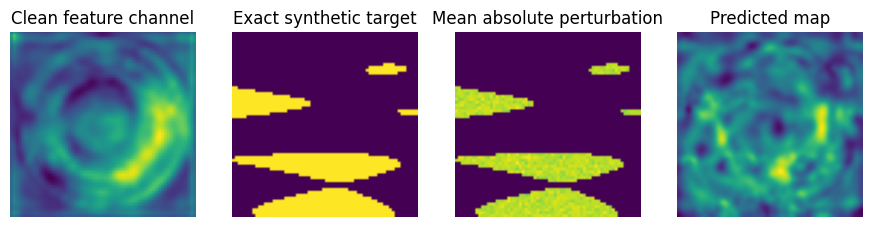

,trial,image_auroc,pixel_ap,last_margin,seconds
0,04-pilot-lite-bottle-s2026-v1,0.390625,0.177820,0.994697,19.944605
1,04-pilot-lite-noise05-bottle-s2026-v1,0.812500,0.264044,0.864753,19.877754


In [9]:
sources=feature_cache(extractor,fit.iloc[32:40],8)
head=model_for(config).cuda().eval()
head.load_state_dict(torch.load(ROOT/diagnostic['checkpoint'],weights_only=True,map_location='cpu')['state_dict'])
with torch.no_grad():
    z=sources.batch(range(8));a=head.adapter(z)
    perturbed,mask,label=feature_anomalies(a,torch.Generator().manual_seed(9901),torch.Generator(device='cuda').manual_seed(9902),noise_std=.05)
    seg,score=head.discriminate(perturbed)
    index=int(torch.where(label>0)[0][0]);delta=(perturbed-torch.cat([a,a])).abs().mean(1)
    maps=anomaly_maps(seg)
    assert torch.isfinite(maps).all() and torch.isfinite(score).all()
    assert torch.equal(delta.ne(0),mask[:,0].bool())
fig,axes=plt.subplots(1,4,figsize=(11,3))
for ax,value,title in zip(axes,[a[index%8,0],mask[index,0],delta[index],maps[index]],['Clean feature channel','Exact synthetic target','Mean absolute perturbation','Predicted map']):
    ax.imshow(value.cpu(),cmap='viridis');ax.set_title(title);ax.axis('off')
plt.show()
display(pd.DataFrame([dict(trial=r['experiment_id'],image_auroc=r['development']['candidates']['head']['auroc'],pixel_ap=r['development']['candidates']['head']['pixel_ap'],last_margin=r['history'][-1]['margin_loss'],seconds=r['wall_seconds']) for r in [pilot,diagnostic]]))


## Gate and next research stages
The measured pilot report and diagnostic decision are stored alongside the notebook. No official test metrics, threshold calibration, frozen final configuration or all-category completeness is claimed here. The next step depends on demonstrated learning on normal-derived synthetic proxies, not a lower loss alone.

The preregistered bounded development study covers bottle/cable/carpet/tile, adaptation, noise and loss behavior, with head/max/top1% aggregation. Calibration will remain separate: higher q95 image and q99.5 pixel normal quantiles, strict `>` decisions, sample counts and uncertainty. Final fitting must precede official test evaluation; no retraining after inspection.

## Comparison and limitations at this stage
No comparison to completed Basic CNN, Autoencoder or PatchCore quality is justified from a tiny synthetic pilot. Prior exact stored results remain unchanged. The future comparison must include matched category scores, precision/recall/FPR/localization, paired uncertainty and measured inference cost, with special attention to leather/carpet false positives and screw detection. Synthetic discrimination may not transfer to real defects; a 64-grid feature representation can lose fine details; tiny held-out sets produce unstable diagnostics; reduced training and widths differ from the publication.

Raw images, weights, dense caches and checkpoints remain local and ignored. This public notebook contains genuine compact outputs. Its training cell executed live; the earlier reference/Lite record was explicitly replayed. The experiment registry is append-only under [experiments](../experiments/), with configurations, hashes and decisions. Full local executed notebook: `outputs/supersimplenet/04_supersimplenet.pilot.executed.ipynb`.
